# 04 · Avaliação do pipeline RAG

Roda o conjunto `evaluation/questions.yaml` e analisa:
- decisões do guardrail (responder × recusar)
- precisão das evidências (proxy por regex de tema)
- extração e respeito aos filtros de metadados

> As células de avaliação usam `generate=False` (só recuperação e guardrail, sem gastar cota).
> A última célula gera uma resposta completa com o Gemini (requer `LLM_API_KEY` no `.env`).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 200)

In [2]:
import yaml
from voc_rag.pipeline import VoCPipeline

pipeline = VoCPipeline.from_settings()
questions = yaml.safe_load((ROOT / "evaluation/questions.yaml").read_text(encoding="utf-8"))["questions"]

In [3]:
rows = []
for q in questions:
    r = pipeline.ask(q["question"], generate=False)
    sig = r.trace.guardrail["signals"]
    rows.append({"id": q["id"], "esperado": q["expected"], "status": r.status.value,
                 "margem_escopo": sig["scope_margin"], "suporte_lexical": sig["lexical_support"],
                 "relevantes": sig["relevant_count"], "motivo": r.trace.guardrail["reason"],
                 "filtros": r.trace.filters_applied})
res = pd.DataFrame(rows)
res

,id,esperado,status,margem_escopo,suporte_lexical,relevantes,motivo,filtros
0,q01_problemas_gerais,answer,retrieval_only,0.0532,-1,102,102 avaliações relevantes (melhor similaridade 0.890),nota 1-3
1,q02_entrega,answer,retrieval_only,0.0777,4036,105,105 avaliações relevantes (melhor similaridade 0.919),nota 1-3
2,q03_elogios,answer,retrieval_only,0.0851,-1,84,84 avaliações relevantes (melhor similaridade 0.898),nota 4-5
3,q04_insatisfeitos,answer,retrieval_only,0.0430,-1,65,65 avaliações relevantes (melhor similaridade 0.965),nota 1-2
4,q05_evidencias_prazo,answer,retrieval_only,0.0274,840,110,110 avaliações relevantes (melhor similaridade 0.922),nota 1-3
5,q06_qualidade,answer,retrieval_only,0.0582,2800,109,109 avaliações relevantes (melhor similaridade 0.938),nenhum
6,q07_nota_baixa,answer,retrieval_only,0.0301,-1,70,70 avaliações relevantes (melhor similaridade 0.890),nota 1-2
7,q08_categoria_elogios,answer,retrieval_only,0.0675,-1,82,82 avaliações relevantes (melhor similaridade 0.903),nota 4-5; categorias: cama_mesa_banho
8,q09_entrega_atrasada,answer,retrieval_only,0.0674,175,97,97 avaliações relevantes (melhor similaridade 0.950),entrega: atrasado
9,q10_celulares_2018,answer,retrieval_only,0.0598,37,63,63 avaliações relevantes (melhor similaridade 0.889),nota 1-3; categorias: telefonia; período: 2018-01 a 2018-12


decisões corretas: 19 / 19


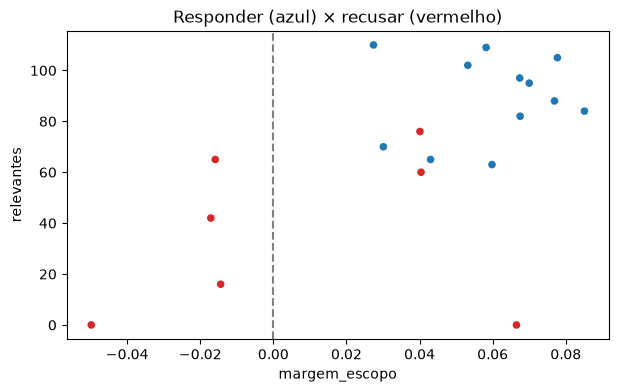

In [4]:
ax = res.plot.scatter(x="margem_escopo", y="relevantes",
                      c=res["esperado"].map({"answer": "tab:blue", "refuse": "tab:red"}),
                      figsize=(7, 4), title="Responder (azul) × recusar (vermelho)")
ax.axvline(pipeline.settings.scope_margin, ls="--", c="gray")
res["acertou"] = (res["status"].isin(["out_of_scope", "insufficient_evidence"])) == (res["esperado"] == "refuse")
print("decisões corretas:", res["acertou"].sum(), "/", len(res))

## Inspeção de uma resposta completa

In [5]:
r = pipeline.ask("Quais são os principais problemas relatados nas avaliações com nota baixa?")
print(r.status.value, "|", r.trace.filters_applied, "\n")
print(r.answer)
print("\n--- início do contexto enviado ao LLM ---")
print(r.trace.context_preview[:1500])

answered | nota 1-2 

Os principais problemas relatados nas avaliações com nota baixa na amostra concentram-se em defeitos de funcionamento, falhas na entrega (atrasos e não recebimento), divergências nos itens enviados, itens faltantes no pedido e dificuldade de atendimento e suporte.

Abaixo estão os padrões organizados do mais para o menos frequente na amostra:

1. **Problemas com o produto (defeitos de funcionamento ou ativação):** Clientes relataram que os produtos vieram com defeito ou com problemas para ativar e funcionar [E1][E7][E12].
2. **Problemas na entrega (atrasos, não recebimento e cancelamento):** Foram relatados problemas gerais de entrega associados aos Correios, atrasos, pedidos não entregues, pedidos cancelados e falta de recebimento do produto no prazo [E3][E4][E5][E14].
3. **Erros no envio (produto diferente do comprado):** Clientes mencionaram que receberam mercadorias diferentes do que foi solicitado, como receber a cor preta em vez da vermelha ou receber um ite